In [ ]:
import pandas as pd
import torch
import torch.nn as nn
import numpy as np
import time
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, balanced_accuracy_score
from matplotlib import pyplot as plt

# 1)

## Subir datasets de dígitos (train)

In [ ]:
from google.colab import files
uploaded = files.upload()  # 1_digits_train.txt
!ls

Saving 1_digits_train.txt to 1_digits_train.txt
1_digits_train.txt  sample_data


In [ ]:
from google.colab import files
uploaded = files.upload()  # 1_digits_test.txt
!ls

Saving 1_digits_test.txt to 1_digits_test.txt
1_digits_test.txt  1_digits_train.txt  sample_data


## Leer dataset de dígitos

In [ ]:
column_names = ["feat" + str(i) for i in range(64)]
column_names.append("class")

In [ ]:
df_train_val = pd.read_csv('1_digits_train.txt', names = column_names)
df_train_val

,feat0,feat1,feat2,feat3,feat4,feat5,feat6,feat7,feat8,feat9,...,feat55,feat56,feat57,feat58,feat59,feat60,feat61,feat62,feat63,class
0,0,0,5,13,9,1,0,0,0,0,...,0,0,0,6,13,10,0,0,0,0
1,0,0,0,12,13,5,0,0,0,0,...,0,0,0,0,11,16,10,0,0,1
2,0,0,0,4,15,12,0,0,0,0,...,0,0,0,0,3,11,16,9,0,2
3,0,0,7,15,13,1,0,0,0,8,...,0,0,0,7,13,13,9,0,0,3
4,0,0,0,1,11,0,0,0,0,0,...,0,0,0,0,2,16,4,0,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4342,0,0,9,11,0,0,0,0,0,7,...,0,0,0,8,12,12,15,10,0,2
4343,0,0,6,15,2,0,0,0,0,0,...,0,0,0,7,16,16,10,1,0,6
4344,0,0,15,16,16,14,0,0,0,0,...,0,0,0,14,11,0,0,0,0,7
4345,0,0,0,1,15,11,0,0,0,0,...,0,0,0,0,1,16,10,0,0,4


In [ ]:
df_test = pd.read_csv('1_digits_test.txt', names = column_names)
df_test

,feat0,feat1,feat2,feat3,feat4,feat5,feat6,feat7,feat8,feat9,...,feat55,feat56,feat57,feat58,feat59,feat60,feat61,feat62,feat63,class
0,0,0,13,12,10,12,8,0,0,2,...,0,0,0,10,16,16,8,0,0,5
1,0,0,8,16,14,4,0,0,0,5,...,0,0,0,10,16,14,12,2,0,9
2,0,0,0,7,16,0,0,0,0,0,...,0,0,0,0,9,15,1,0,0,4
3,0,0,2,14,9,2,0,0,0,0,...,0,0,0,2,14,14,2,0,0,0
4,0,1,16,16,15,3,0,0,0,0,...,0,0,0,16,6,0,0,0,0,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1267,0,0,5,13,11,2,0,0,0,2,...,0,0,0,8,13,15,10,1,0,9
1268,0,0,0,1,12,1,0,0,0,0,...,0,0,0,0,4,9,0,0,0,4
1269,0,0,3,15,0,0,0,0,0,0,...,0,0,0,4,14,16,9,0,0,6
1270,0,0,6,16,2,0,0,0,0,0,...,0,0,0,5,16,16,16,5,0,6


In [ ]:
df_train, df_val = train_test_split(df_train_val, test_size = 0.3, random_state = 10)

In [ ]:
scaler = StandardScaler().fit(df_train.iloc[:,0:64])
df_train.iloc[:,0:64] = scaler.transform(df_train.iloc[:,0:64])
df_val.iloc[:,0:64] = scaler.transform(df_val.iloc[:,0:64])
df_test.iloc[:,0:64] = scaler.transform(df_test.iloc[:,0:64])

In [ ]:
df_train

,feat0,feat1,feat2,feat3,feat4,feat5,feat6,feat7,feat8,feat9,...,feat55,feat56,feat57,feat58,feat59,feat60,feat61,feat62,feat63,class
4026,0,-0.338570,0.797238,0.535297,-0.599203,-1.007598,-0.412556,-0.13043,-0.045374,1.329217,...,-0.206188,0,-0.302452,0.078492,-0.427291,0.468026,1.548367,0.696964,-0.186744,9
1548,0,-0.338570,-0.269346,0.999221,0.985819,0.594099,-0.412556,-0.13043,-0.045374,-0.619760,...,-0.206188,0,-0.302452,-0.121990,0.248408,0.876852,1.378118,-0.527715,-0.186744,3
1709,0,-0.338570,-0.482663,0.535297,0.759387,0.594099,-0.412556,-0.13043,-0.045374,-0.619760,...,-0.206188,0,-0.302452,-0.723436,-0.427291,0.876852,1.548367,-0.037843,-0.186744,1
2195,0,2.026364,1.863823,-0.392551,-2.410657,-1.007598,-0.412556,-0.13043,-0.045374,1.329217,...,-0.206188,0,1.890776,1.481867,-0.652523,-0.758451,0.356618,1.186836,-0.186744,2
1216,0,2.026364,0.797238,0.767259,0.985819,1.661897,0.191388,-0.13043,-0.045374,2.953365,...,-0.206188,0,-0.302452,1.281385,0.924106,0.672439,0.356618,-0.282779,-0.186744,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2009,0,-0.338570,-1.122613,-2.248248,-0.599203,1.839863,0.493359,-0.13043,-0.045374,-0.619760,...,-0.206188,0,-0.302452,-1.124400,-2.679617,0.468026,-0.664881,-0.527715,-0.186744,9
1180,0,0.843897,0.583922,-0.392551,0.532956,0.772065,-0.412556,-0.13043,-0.045374,3.278195,...,-0.206188,0,-0.302452,1.281385,0.924106,0.468026,0.867368,0.452028,-0.186744,3
3441,0,-0.338570,-0.269346,-0.160589,0.985819,0.950031,-0.110584,-0.13043,-0.045374,0.354728,...,-0.206188,0,-0.302452,0.078492,0.473640,-2.393755,-1.175631,-0.527715,-0.186744,9
1344,0,-0.338570,1.223872,0.999221,0.985819,0.238166,-0.412556,-0.13043,-0.045374,0.029899,...,0.911859,0,-0.302452,0.880421,0.924106,0.876852,1.548367,3.391260,6.008192,2


## Crear datasets y dataloaders para pytorch (train)

In [ ]:
# Crear datasets
feats_train = df_train.to_numpy()[:,0:64].astype(np.float32)
labels_train = df_train.to_numpy()[:,64].astype(int)
dataset_train = [ {"features":feats_train[i,:], "labels":labels_train[i]} for i in range(feats_train.shape[0]) ]

feats_val = df_val.to_numpy()[:,0:64].astype(np.float32)
labels_val = df_val.to_numpy()[:,64].astype(int)
dataset_val = [ {"features":feats_val[i,:], "labels":labels_val[i]} for i in range(feats_val.shape[0]) ]

feats_test = df_test.to_numpy()[:,0:64].astype(np.float32)
labels_test = df_test.to_numpy()[:,64].astype(int)
dataset_test = [ {"features":feats_test[i,:], "labels":labels_test[i]} for i in range(feats_test.shape[0]) ]

In [ ]:
dataset_train[0]["features"]

array([ 0.        , -0.33856955,  0.79723847,  0.5352972 , -0.599203  ,
       -1.0075984 , -0.41255572, -0.13042974, -0.04537399,  1.3292172 ,
        0.84617096, -1.7056739 ,  1.1455593 , -0.37681162, -0.5318587 ,
       -0.13236995, -0.03683547,  0.6990294 ,  0.74147123, -1.0136253 ,
       -0.1916465 ,  0.80835044, -0.55975205, -0.11006276, -0.03141921,
       -0.77677244,  0.12759452,  0.8371088 ,  0.52092284,  1.3879347 ,
       -0.6414221 , -0.04802525, -0.03141921, -0.65898514, -1.2304808 ,
       -0.6613772 , -0.90222865,  0.50866824, -0.2618292 ,  0.        ,
       -0.08703703, -0.5121471 , -1.0191833 , -1.1009529 , -1.2571743 ,
        0.06224909,  0.34282276, -0.08613759, -0.05445073, -0.41844317,
        1.4544101 , -0.13090841, -0.5028831 ,  0.13292219,  0.8360826 ,
       -0.20618823,  0.        , -0.30245203,  0.07849249, -0.42729056,
        0.46802634,  1.5483674 ,  0.69696444, -0.18674414], dtype=float32)

In [ ]:
# Crear dataloaders
DataloaderTrain = torch.utils.data.DataLoader(dataset_train, batch_size=128, shuffle=True, num_workers=0)
DataloaderVal = torch.utils.data.DataLoader(dataset_val, batch_size=128, shuffle=True, num_workers=0)
DataloaderTest = torch.utils.data.DataLoader(dataset_test, batch_size=128, shuffle=True, num_workers=0)

## Crear modelo

In [ ]:
model = nn.Sequential(
          nn.Linear(64, 10),
          nn.ReLU(),
          nn.Linear(10,10)
        )

In [ ]:
device = torch.device('cuda')

model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

## Entrenamiento

In [ ]:
start = time.time()

# loop over the dataset multiple times
for epoch in range(250):
  model.train()
  # Train on the current epoch
  for i, data in enumerate(DataloaderTrain, 0):
    # Process the current batch
    inputs = data["features"].to(device)
    labels = data["labels"].to(device)
    # zero the parameter gradients
    optimizer.zero_grad()
    # forward + backward + optimize
    outputs = model(inputs)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

  model.eval()
  with torch.no_grad():
    # To do: compute validation loss for current epoch
    pass

  # To do: print train/validation loss for the current epoch
  print('epoch %d' % (epoch))

end = time.time()
print('Finished Training, total time %f seconds' % (end - start))

epoch 0
epoch 1
epoch 2
epoch 3
epoch 4
epoch 5
epoch 6
epoch 7
epoch 8
epoch 9
epoch 10
epoch 11
epoch 12
epoch 13
epoch 14
epoch 15
epoch 16
epoch 17
epoch 18
epoch 19
epoch 20
epoch 21
epoch 22
epoch 23
epoch 24
epoch 25
epoch 26
epoch 27
epoch 28
epoch 29
epoch 30
epoch 31
epoch 32
epoch 33
epoch 34
epoch 35
epoch 36
epoch 37
epoch 38
epoch 39
epoch 40
epoch 41
epoch 42
epoch 43
epoch 44
epoch 45
epoch 46
epoch 47
epoch 48
epoch 49
epoch 50
epoch 51
epoch 52
epoch 53
epoch 54
epoch 55
epoch 56
epoch 57
epoch 58
epoch 59
epoch 60
epoch 61
epoch 62
epoch 63
epoch 64
epoch 65
epoch 66
epoch 67
epoch 68
epoch 69
epoch 70
epoch 71
epoch 72
epoch 73
epoch 74
epoch 75
epoch 76
epoch 77
epoch 78
epoch 79
epoch 80
epoch 81
epoch 82
epoch 83
epoch 84
epoch 85
epoch 86
epoch 87
epoch 88
epoch 89
epoch 90
epoch 91
epoch 92
epoch 93
epoch 94
epoch 95
epoch 96
epoch 97
epoch 98
epoch 99
epoch 100
epoch 101
epoch 102
epoch 103
epoch 104
epoch 105
epoch 106
epoch 107
epoch 108
epoch 109
epoch 110


# 2)


In [ ]:
class Model(nn.Module):
  def __init__(self, activation_layer, hidden_size, n_hidden_layers, input_size=64, output_size=10):
    super(Model, self).__init__()
    self.input_layer = nn.Linear(input_size, hidden_size)
    if n_hidden_layers == 2:
      self.hidden_layer = nn.Sequential(nn.ReLU() if activation_layer == 'ReLU' else nn.Tanh() if activation_layer == 'Tanh' else None,
                                        nn.ReLU() if activation_layer == 'ReLU' else nn.Tanh() if activation_layer == 'Tanh' else None)
    elif n_hidden_layers == 1:
      self.hidden_layer = nn.ReLU() if activation_layer == 'ReLU' else nn.Tanh() if activation_layer == 'Tanh' else None
    self.output_layer = nn.Linear(hidden_size, output_size)
    self.n_hidden_layers = n_hidden_layers

  def forward(self, x):
    out = self.input_layer(x)
    if self.hidden_layer is not None:
      if self.n_hidden_layers == 2:
        for layer in self.hidden_layer:
          out = layer(out)
      elif self.n_hidden_layers == 1:
        out = self.hidden_layer(out)
    out = self.output_layer(out)
    return out

In [ ]:
def ColorSelector(accuracy):
  if accuracy > 0.95:
      cmap = 'Greens'
  elif accuracy > 0.9:
      cmap = 'Blues'
  elif accuracy > 0.8:
      cmap = 'Reds'
  else:
      cmap = 'Greys'
  return cmap

In [ ]:
def TrainModel(model, Patience=5):
  # Definición de dispositivo
  device = torch.device('cuda')
  # Se envia al modelo al dispositivo
  model = model.to(device)
  # Definición de la función de perdida
  Criterion = nn.CrossEntropyLoss()
  # Definición del optimizador
  Optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
  # Inicio del tiempo
  StartTime = time.time()
  # Listas
  TrainingLossList = []
  ValidationLossList = []
  EpochsList = []
  # Parametros del early stopping
  PatienceCounter = 0
  BestValidationLoss = float('inf')
  # Bucle sobre el dataset 1000 veces
  for epoch in range(1000):
    # Modelo en modo entrenamiento
    model.train()
    # Parametros de las perdidas
    TrainingLossSumatory = 0.0
    TrainingBatches = 0
    ValidationLossSumatory = 0.0
    ValidationBatches = 0
    # Entrenamiento para la epoca actual
    for i, data in enumerate(DataloaderTrain, 0):
      # Procesar el lote actual
      TrainingInputs = data["features"].to(device)
      TrainingLabels = data["labels"].to(device)
      # Poner en cero los parametros del gradiente
      Optimizer.zero_grad()
      # Foward + Backward + Optimize
      # Salidas del modelo sobre el conjunto de entrenamiento
      TrainingOutputs = model(TrainingInputs)
      # Perdida del modelo sobre el conjunto de entrenamiento
      TrainingLoss = Criterion(TrainingOutputs, TrainingLabels)
      # Backward
      TrainingLoss.backward()
      # Optimize
      Optimizer.step()
      # Parametros para el calculo del promedio de la perdida en el entrenamiento
      TrainingLossSumatory += TrainingLoss.detach().cpu().item()
      TrainingBatches += 1
    # Calculo y guardado de la perdida promedio en el bucle de entrenamiento
    TrainingLossAverage = TrainingLossSumatory / TrainingBatches
    TrainingLossList.append(TrainingLossAverage)
    # Modelo en evaluación
    model.eval()
    # Se desactiva el computo de gradientes
    with torch.no_grad():
      # Para cada indice y dato en el enumerado del Dataloader del conjunto de validación
      for i, data in enumerate(DataloaderVal):
        # Procesa el lote actual
        ValidationInputs = data["features"].to(device)
        ValidationLabels = data["labels"].to(device)
        # Salidas del modelo sobre el conjunto de validación
        ValidationOutputs = model(ValidationInputs)
        # Perdida  del modelo sobre el conjunto de validación
        ValidationLoss = Criterion(ValidationOutputs, ValidationLabels)
        # Parametros para el calculo del promedio de la perdida en la validación
        ValidationLossSumatory += ValidationLoss.detach().cpu().item()
        ValidationBatches += 1
      # Calculo y guardado de la perdida promedio en el bucle de validación
      ValidationLossAverage = ValidationLossSumatory / ValidationBatches
      ValidationLossList.append(ValidationLossAverage)
    # Guardar la Epoca
    EpochsList.append(epoch)
    # Imprimir epoca, promedio de perdida en entrenamiento y promedio de perdida en validación
    print(f'epoch {epoch}')
    print(f'Training loss: {TrainingLossAverage:.4f}')
    print(f'Validation loss: {ValidationLossAverage:.4f}')
    # Logica de patience early stopping
    # Si la perdida del promedio del conjunto de validación es menor que la perdida del mejor conjunto de validación
    if ValidationLossAverage < BestValidationLoss:
      # Asignar como mejor perdida a la perdida promedio del conjunto de validación
      BestValidationLoss = ValidationLossAverage
      # Asignar a 0 el contador de paciencia
      PatienceCounter = 0
    # En otro caso
    else:
      # Aumentar en 1 el contador de paciencia
      PatienceCounter += 1
    # Si el contador de paciencia es mayor a la paciencia
    if PatienceCounter > Patience:
      # Imprime mensaje de early stopping
      print(f'Early stoping at epoch {epoch}')
      # Termina el bucle
      break
  # Termino del tiempo
  EndTime = time.time()
  # Imprime mensaje de termino
  print('Finished Training, total time %f seconds' % (EndTime - StartTime))
  # Grafico de perdidas versus epocas
  plt.figure(figsize=(8,6))
  plt.plot(EpochsList, TrainingLossList, label='Training loss')
  plt.plot(EpochsList, ValidationLossList, label='Validation loss')
  plt.title('Losses v/s Epochs')
  plt.xlabel('Epochs')
  plt.ylabel('Losses')
  plt.legend()
  plt.show()
  # Matriz de confusión normalizada y Accuracy sobre el conjunto de entrenamiento
  AccuracyScoreTraining = accuracy_score(TrainingLabels.detach().cpu().numpy(), torch.argmax(TrainingOutputs, dim=1).detach().cpu().numpy())
  ConfusionMatrixTraining = confusion_matrix(torch.argmax(TrainingOutputs, dim=1).detach().cpu().numpy(), TrainingLabels.detach().cpu().numpy(), normalize='true')
  plt.figure(figsize=(8,6))
  plt.imshow(ConfusionMatrixTraining, cmap=plt.get_cmap(ColorSelector(AccuracyScoreTraining)))
  for i in range(ConfusionMatrixTraining.shape[0]):
      for j in range(ConfusionMatrixTraining.shape[1]):
          plt.text(j, i, format(ConfusionMatrixTraining[i,j], ".2f"), ha="center", va="center", color="black")
  plt.colorbar(label=f'Accuracy: {AccuracyScoreTraining:.2f}')
  plt.title(f'Confusion Matrix (train set)')
  plt.show()
  # Matriz de confusión normalizada y Accurac normalizado sobre el conjunto de validación
  AccuracyScoreValidation = balanced_accuracy_score(ValidationLabels.detach().cpu().numpy(), torch.argmax(ValidationOutputs, dim=1).detach().cpu().numpy())
  ConfusionMatrixValidation = confusion_matrix(torch.argmax(ValidationOutputs, dim=1).detach().cpu().numpy(), ValidationLabels.detach().cpu().numpy(), normalize='true')
  plt.figure(figsize=(8,6))
  plt.imshow(ConfusionMatrixValidation, cmap=plt.get_cmap(ColorSelector(AccuracyScoreValidation)))
  for i in range(ConfusionMatrixValidation.shape[0]):
      for j in range(ConfusionMatrixValidation.shape[1]):
          plt.text(j, i, format(ConfusionMatrixValidation[i, j], ".2f"), ha="center", va="center", color="black")
  plt.colorbar(label=f'Balanced Accuracy: {AccuracyScoreValidation:.2f}')
  plt.title(f'Confusion Matrix (validation set)')
  plt.show()

## a)

Model(
  (input_layer): Linear(in_features=64, out_features=10, bias=True)
  (hidden_layer): ReLU()
  (output_layer): Linear(in_features=10, out_features=10, bias=True)
)
epoch 0
Training loss: 2.2993
Validation loss: 2.2089
epoch 1
Training loss: 2.1426
Validation loss: 2.0406
epoch 2
Training loss: 1.9688
Validation loss: 1.8571
epoch 3
Training loss: 1.7626
Validation loss: 1.6319
epoch 4
Training loss: 1.5574
Validation loss: 1.4626
epoch 5
Training loss: 1.3743
Validation loss: 1.3071
epoch 6
Training loss: 1.2167
Validation loss: 1.1383
epoch 7
Training loss: 1.0765
Validation loss: 1.0051
epoch 8
Training loss: 0.9500
Validation loss: 0.8744
epoch 9
Training loss: 0.8360
Validation loss: 0.7631
epoch 10
Training loss: 0.7365
Validation loss: 0.6906
epoch 11
Training loss: 0.6510
Validation loss: 0.6225
epoch 12
Training loss: 0.5802
Validation loss: 0.5481
epoch 13
Training loss: 0.5223
Validation loss: 0.4859
epoch 14
Training loss: 0.4738
Validation loss: 0.4506
epoch 15
Train

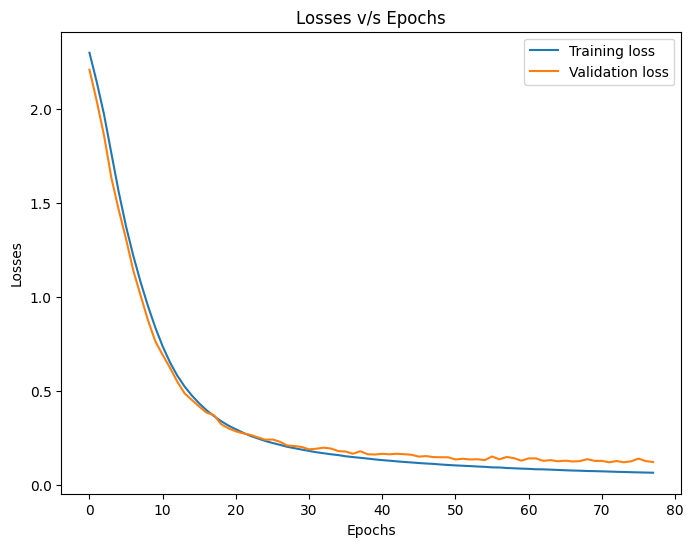

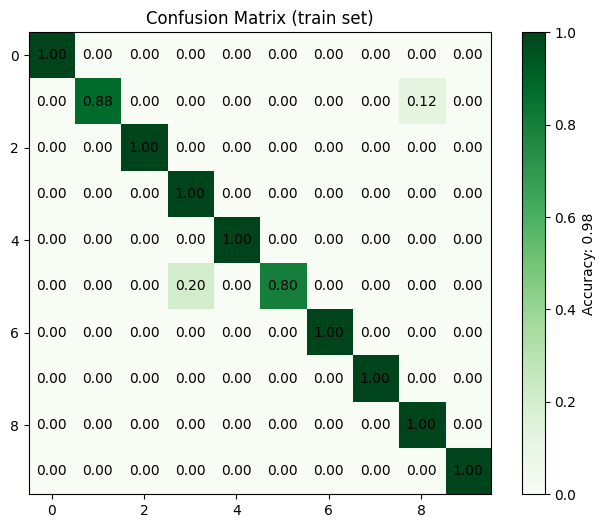

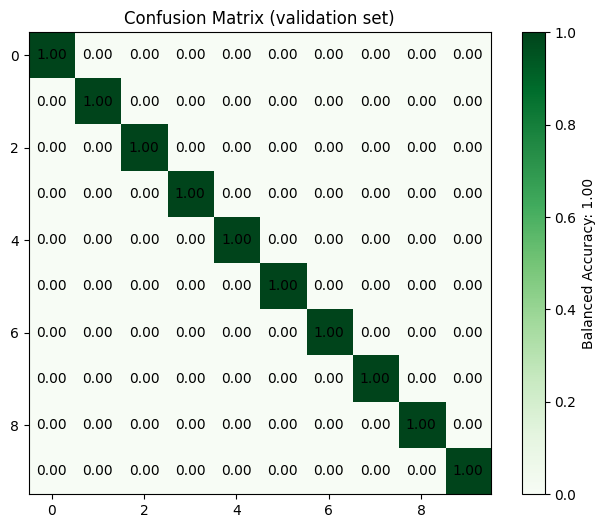

In [ ]:
model_1 = Model('ReLU', 10, 1)
print(model_1)
TrainModel(model_1)

## b)


Model(
  (input_layer): Linear(in_features=64, out_features=40, bias=True)
  (hidden_layer): ReLU()
  (output_layer): Linear(in_features=40, out_features=10, bias=True)
)
epoch 0
Training loss: 2.1439
Validation loss: 1.9031
epoch 1
Training loss: 1.7014
Validation loss: 1.4466
epoch 2
Training loss: 1.2419
Validation loss: 1.0006
epoch 3
Training loss: 0.8506
Validation loss: 0.7027
epoch 4
Training loss: 0.5967
Validation loss: 0.4941
epoch 5
Training loss: 0.4442
Validation loss: 0.3859
epoch 6
Training loss: 0.3522
Validation loss: 0.3239
epoch 7
Training loss: 0.2951
Validation loss: 0.2746
epoch 8
Training loss: 0.2544
Validation loss: 0.2356
epoch 9
Training loss: 0.2244
Validation loss: 0.2132
epoch 10
Training loss: 0.2012
Validation loss: 0.2016
epoch 11
Training loss: 0.1827
Validation loss: 0.2050
epoch 12
Training loss: 0.1682
Validation loss: 0.1837
epoch 13
Training loss: 0.1545
Validation loss: 0.1580
epoch 14
Training loss: 0.1429
Validation loss: 0.1507
epoch 15
Train

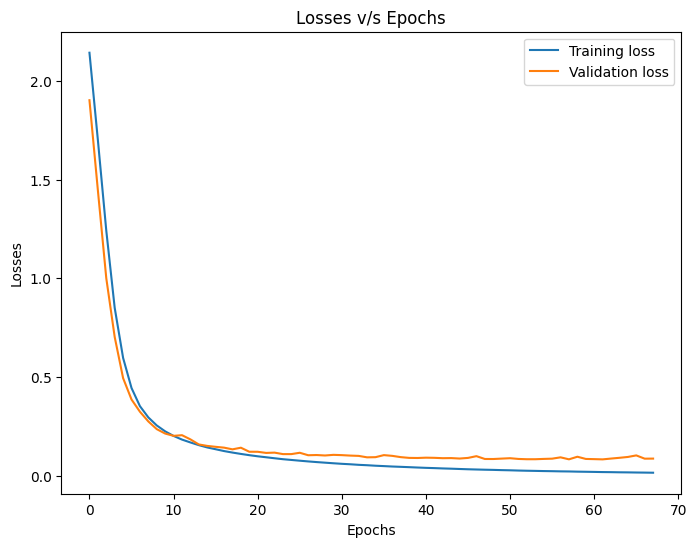

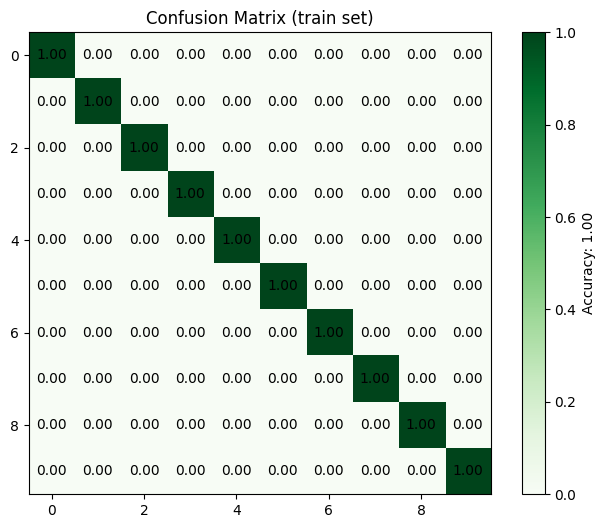

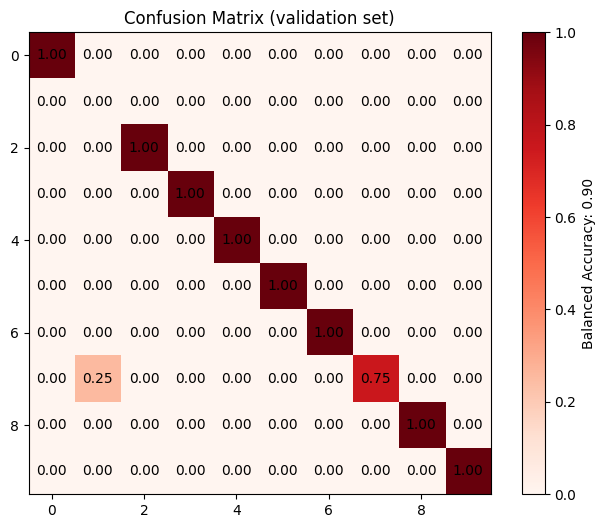

In [ ]:
model_2 = Model('ReLU', 40, 1)
print(model_2)
TrainModel(model_2)

## c)


Model(
  (input_layer): Linear(in_features=64, out_features=10, bias=True)
  (hidden_layer): Tanh()
  (output_layer): Linear(in_features=10, out_features=10, bias=True)
)
epoch 0
Training loss: 2.1890
Validation loss: 2.0555
epoch 1
Training loss: 1.9484
Validation loss: 1.8352
epoch 2
Training loss: 1.7519
Validation loss: 1.6529
epoch 3
Training loss: 1.5822
Validation loss: 1.4884
epoch 4
Training loss: 1.4290
Validation loss: 1.3488
epoch 5
Training loss: 1.2893
Validation loss: 1.2090
epoch 6
Training loss: 1.1617
Validation loss: 1.1065
epoch 7
Training loss: 1.0483
Validation loss: 0.9942
epoch 8
Training loss: 0.9491
Validation loss: 0.9012
epoch 9
Training loss: 0.8616
Validation loss: 0.8187
epoch 10
Training loss: 0.7863
Validation loss: 0.7402
epoch 11
Training loss: 0.7210
Validation loss: 0.6913
epoch 12
Training loss: 0.6653
Validation loss: 0.6467
epoch 13
Training loss: 0.6158
Validation loss: 0.5965
epoch 14
Training loss: 0.5718
Validation loss: 0.5619
epoch 15
Train

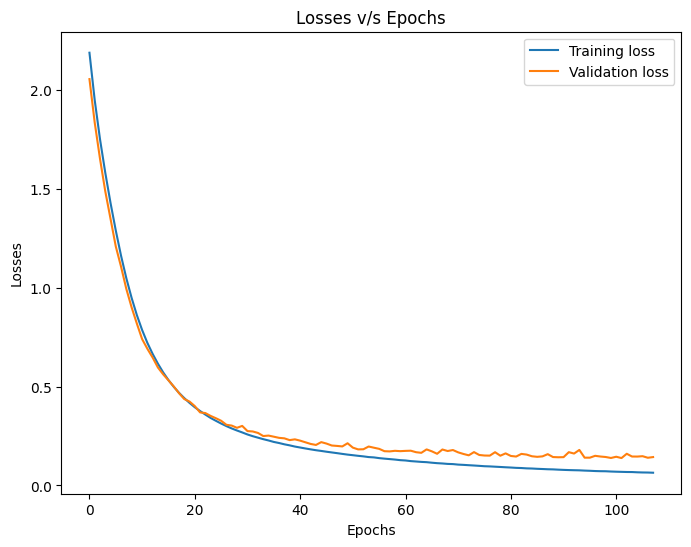

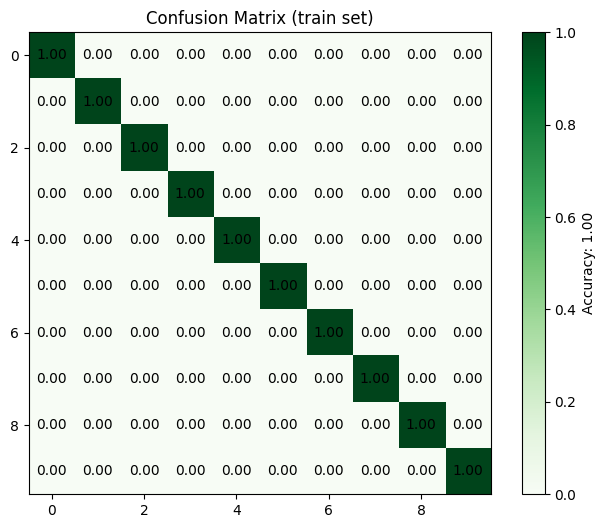

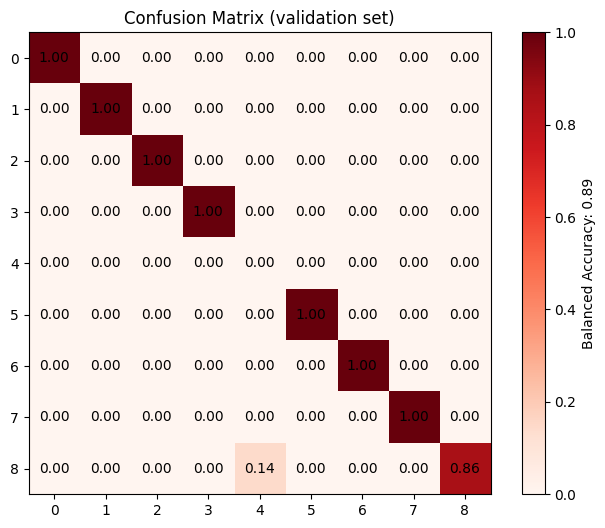

In [ ]:
model_3 = Model('Tanh', 10, 1)
print(model_3)
TrainModel(model_3)

## d)

Model(
  (input_layer): Linear(in_features=64, out_features=40, bias=True)
  (hidden_layer): Tanh()
  (output_layer): Linear(in_features=40, out_features=10, bias=True)
)
epoch 0
Training loss: 2.0634
Validation loss: 1.7908
epoch 1
Training loss: 1.5587
Validation loss: 1.3409
epoch 2
Training loss: 1.1645
Validation loss: 1.0132
epoch 3
Training loss: 0.8719
Validation loss: 0.7592
epoch 4
Training loss: 0.6664
Validation loss: 0.5866
epoch 5
Training loss: 0.5274
Validation loss: 0.4703
epoch 6
Training loss: 0.4308
Validation loss: 0.3983
epoch 7
Training loss: 0.3627
Validation loss: 0.3355
epoch 8
Training loss: 0.3136
Validation loss: 0.3018
epoch 9
Training loss: 0.2771
Validation loss: 0.2656
epoch 10
Training loss: 0.2477
Validation loss: 0.2421
epoch 11
Training loss: 0.2250
Validation loss: 0.2306
epoch 12
Training loss: 0.2056
Validation loss: 0.2127
epoch 13
Training loss: 0.1898
Validation loss: 0.1907
epoch 14
Training loss: 0.1763
Validation loss: 0.1910
epoch 15
Train

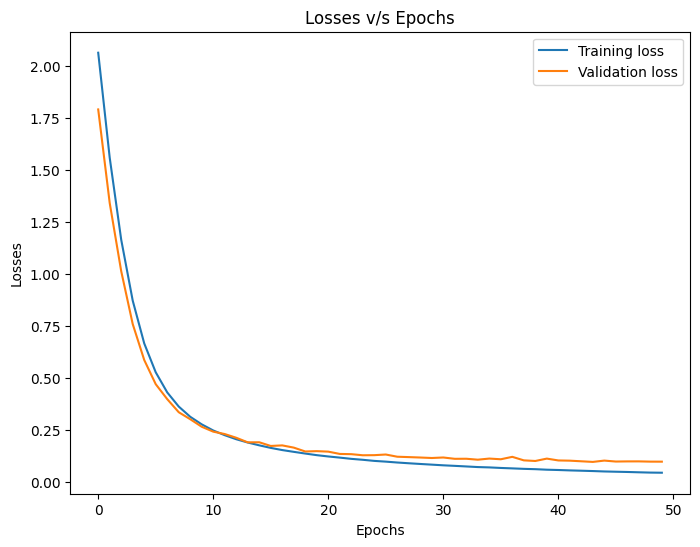

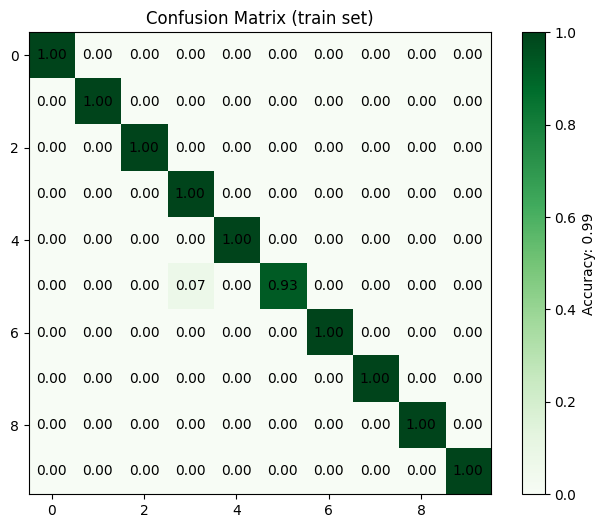

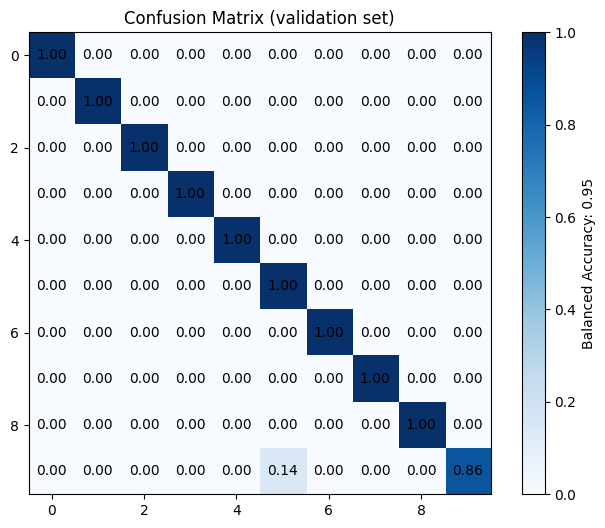

In [ ]:
model_4 = Model('Tanh', 40, 1)
print(model_4)
TrainModel(model_4)

## e)

Model(
  (input_layer): Linear(in_features=64, out_features=10, bias=True)
  (hidden_layer): Sequential(
    (0): ReLU()
    (1): ReLU()
  )
  (output_layer): Linear(in_features=10, out_features=10, bias=True)
)
epoch 0
Training loss: 2.2169
Validation loss: 2.1245
epoch 1
Training loss: 2.0436
Validation loss: 1.9407
epoch 2
Training loss: 1.8596
Validation loss: 1.7489
epoch 3
Training loss: 1.6561
Validation loss: 1.5407
epoch 4
Training loss: 1.4443
Validation loss: 1.3277
epoch 5
Training loss: 1.2419
Validation loss: 1.1623
epoch 6
Training loss: 1.0619
Validation loss: 0.9695
epoch 7
Training loss: 0.9125
Validation loss: 0.8425
epoch 8
Training loss: 0.7893
Validation loss: 0.7236
epoch 9
Training loss: 0.6902
Validation loss: 0.6496
epoch 10
Training loss: 0.6103
Validation loss: 0.5608
epoch 11
Training loss: 0.5433
Validation loss: 0.5039
epoch 12
Training loss: 0.4895
Validation loss: 0.4622
epoch 13
Training loss: 0.4451
Validation loss: 0.4155
epoch 14
Training loss: 0.40

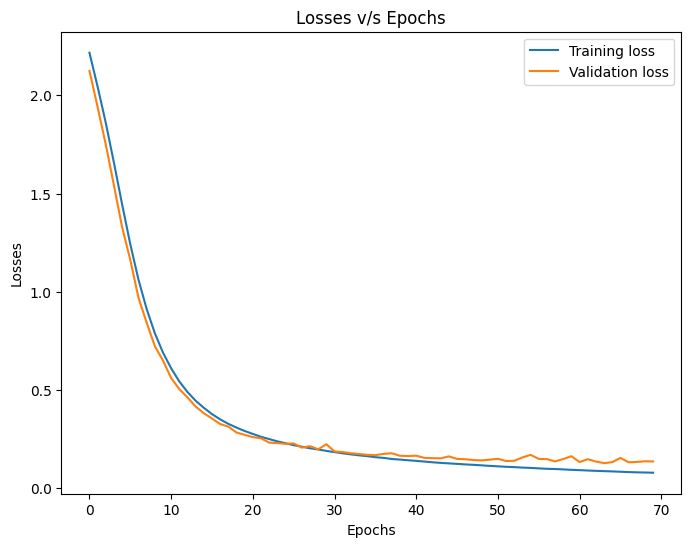

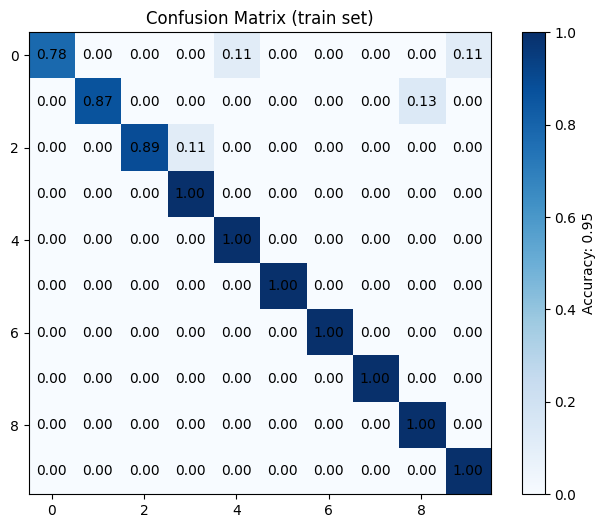

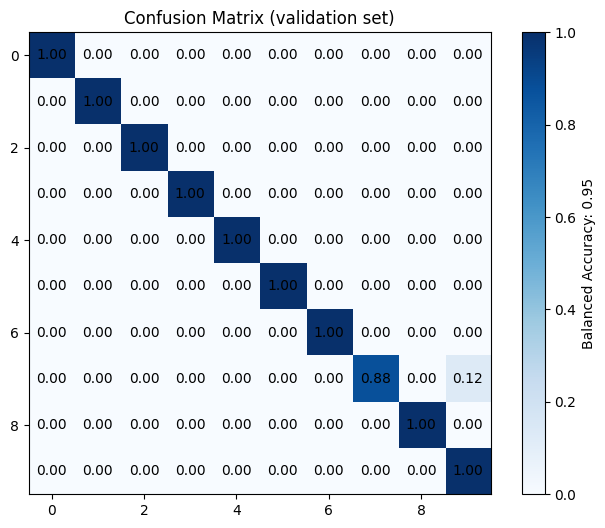

In [ ]:
model_5 = Model('ReLU', 10, 2)
print(model_5)
TrainModel(model_5)

## f)

Model(
  (input_layer): Linear(in_features=64, out_features=40, bias=True)
  (hidden_layer): Sequential(
    (0): ReLU()
    (1): ReLU()
  )
  (output_layer): Linear(in_features=40, out_features=10, bias=True)
)
epoch 0
Training loss: 2.1180
Validation loss: 1.8839
epoch 1
Training loss: 1.6840
Validation loss: 1.4475
epoch 2
Training loss: 1.2383
Validation loss: 1.0185
epoch 3
Training loss: 0.8611
Validation loss: 0.7167
epoch 4
Training loss: 0.6086
Validation loss: 0.5149
epoch 5
Training loss: 0.4547
Validation loss: 0.3953
epoch 6
Training loss: 0.3585
Validation loss: 0.3480
epoch 7
Training loss: 0.2963
Validation loss: 0.2781
epoch 8
Training loss: 0.2526
Validation loss: 0.2600
epoch 9
Training loss: 0.2214
Validation loss: 0.2242
epoch 10
Training loss: 0.1970
Validation loss: 0.2031
epoch 11
Training loss: 0.1773
Validation loss: 0.1861
epoch 12
Training loss: 0.1617
Validation loss: 0.1772
epoch 13
Training loss: 0.1479
Validation loss: 0.1648
epoch 14
Training loss: 0.13

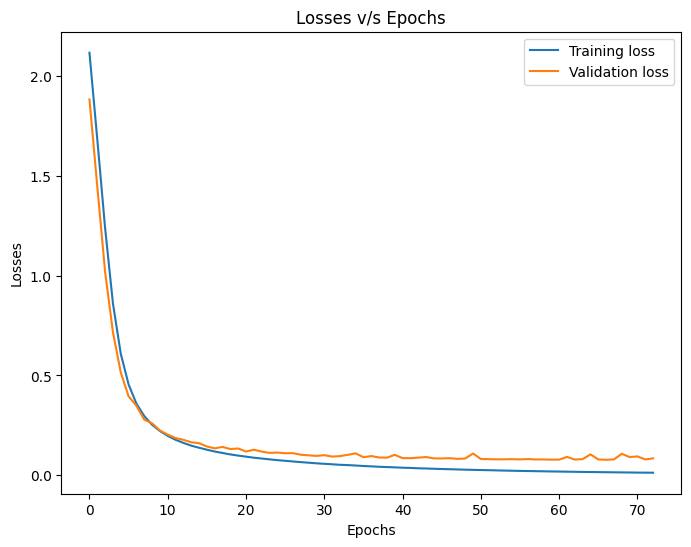

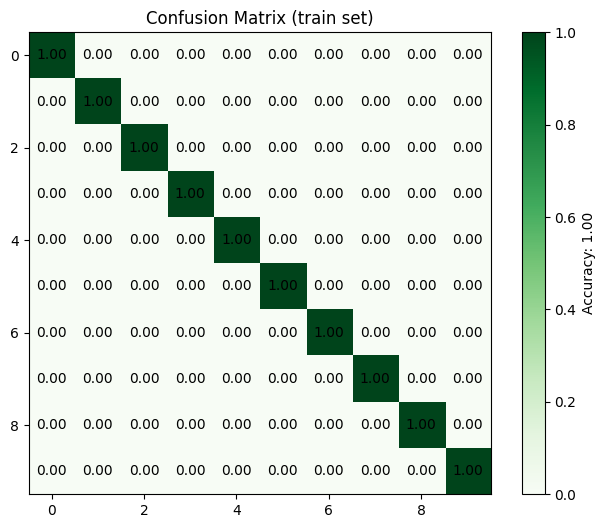

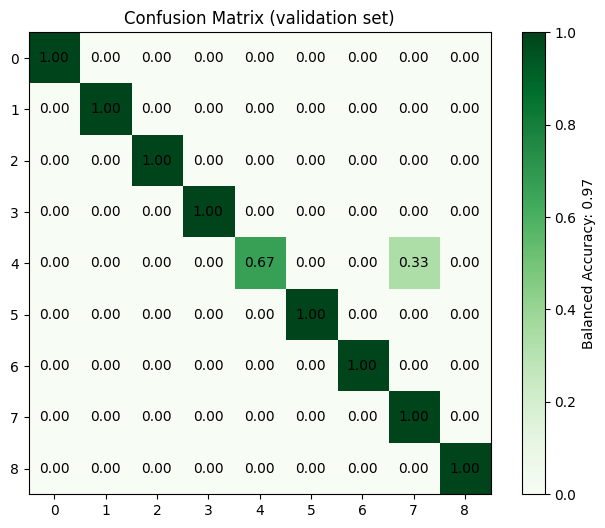

In [ ]:
model_6 = Model('ReLU', 40, 2)
print(model_6)
TrainModel(model_6)

# 3)

In [ ]:
def EvaluateBestModel(model):
  device = torch.device('cuda')
  model = model.to(device)

  TestLossList = []
  with torch.no_grad():
      for i, data in enumerate(DataloaderTest):
        # Process the current batch
        TestInputs = data["features"].to(device)
        TestLabels = data["labels"].to(device)
        TestOutputs = model(TestInputs)

      AccuracyScoreTest = balanced_accuracy_score(TestLabels.detach().cpu().numpy(), torch.argmax(TestOutputs, dim=1).detach().cpu().numpy())
      ConfusionMatrixTest = confusion_matrix(torch.argmax(TestOutputs, dim=1).detach().cpu().numpy(), TestLabels.detach().cpu().numpy(), normalize='true')
      plt.figure(figsize=(8,6))
      plt.imshow(ConfusionMatrixTest, cmap='Greens')
      for i in range(ConfusionMatrixTest.shape[0]):
          for j in range(ConfusionMatrixTest.shape[1]):
              plt.text(j, i, format(ConfusionMatrixTest[i, j], ".2f"), ha="center", va="center", color="black")
      plt.colorbar(label=f'Balanced Accuracy: {AccuracyScoreTest:.2f}')
      plt.title(f'Confusion Matrix (Test set)')
      plt.show()

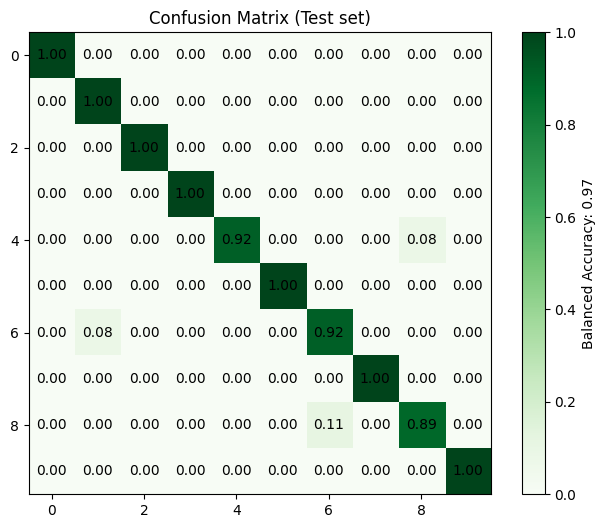

In [ ]:
EvaluateBestModel(model_1)